# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 4</span>

In [6]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Second  Simulation 

---

## Direct Process
**Transition:** Low Entropy $\to$ High Entropy  
*(Evolution from the ordered FCC crystal lattice towards thermal equilibrium)*

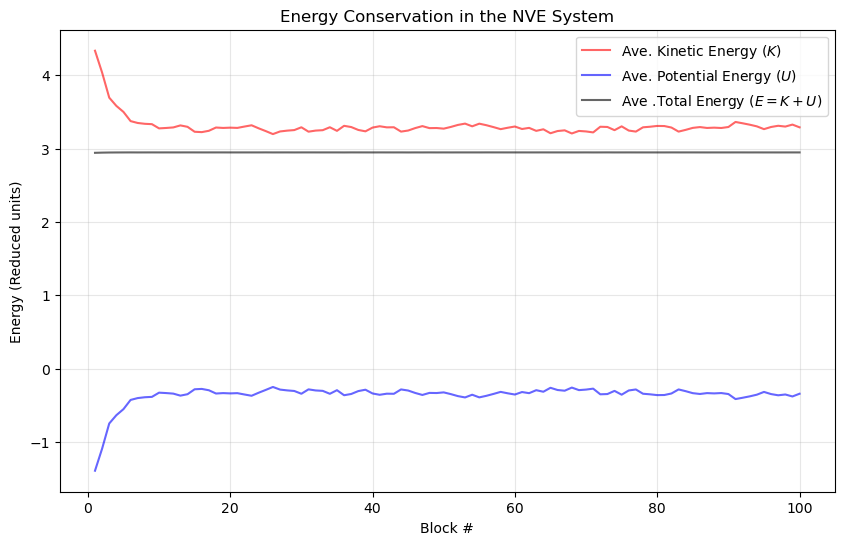

In [8]:


# Carico i dati
data1 = np.loadtxt("3/kinetic_energy.dat")
data2 = np.loadtxt("3/potential_energy.dat")
data3 = np.loadtxt("3/total_energy.dat")

# Definisco le x (blocchi) e le y (energie)
blocks = data1[:, 0]
ke = data1[:, 1]
pe = data2[:, 1]
te=data3[:,1]

plt.figure(figsize=(10,6))

# Plot delle componenti
plt.plot(blocks, ke, label='Ave. Kinetic Energy ($K$)', color='red', alpha=0.6)
plt.plot(blocks, pe, label='Ave. Potential Energy ($U$)', color='blue', alpha=0.6)
plt.plot(blocks, te, label='Ave .Total Energy ($E=K+U$)', color='black', alpha=0.6)

# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

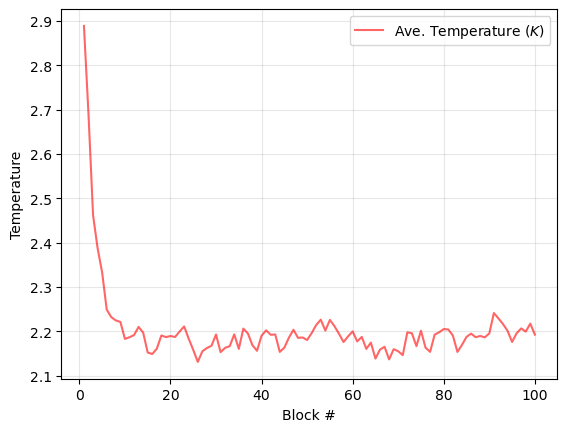

In [10]:
# Carico i dati
data4 = np.loadtxt("3/temperature.dat")
te = data4[:,1]
blocks_te = data4[:, 0]

# Plot delle componenti
plt.plot(blocks_te, te, label='Ave. Temperature ($K$)', color='red', alpha=0.6)

plt.title("")
plt.xlabel("Block #")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


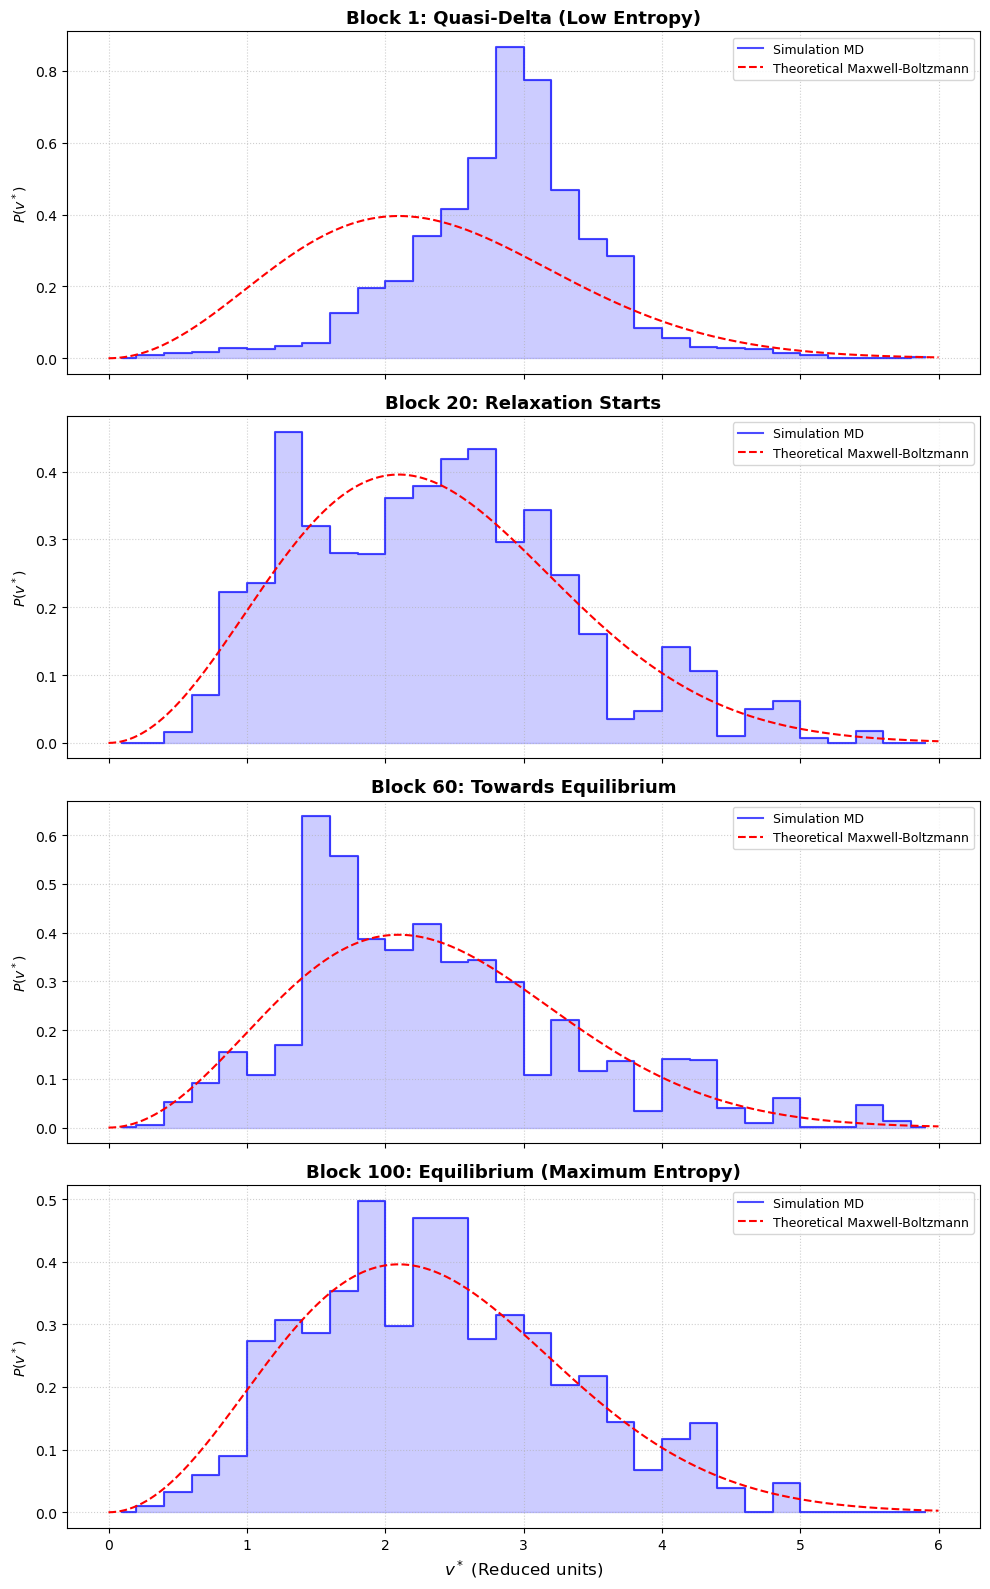

In [12]:
def plot_separated_histograms(filename):
    # Leggiamo il file e separiamo i blocchi
    with open(filename, 'r') as f:
        blocks = [b for b in f.read().split('\n\n\n') if b.strip()]

    # Selezioniamo 4 momenti chiave
    indices = [0, 20, 60, len(blocks)-1]
    titles = [
        'Block 1: Quasi-Delta (Low Entropy)',
        'Block 20: Relaxation Starts',
        'Block 60: Towards Equilibrium',
        'Block 100: Equilibrium (Maximum Entropy)'
    ]

    # Creiamo una figura con 4 grafici sovrapposti
    fig, axes = plt.subplots(4, 1, figsize=(10, 16), sharex=True)
    
    # Valore di Temperatura Effettiva (controlla il tuo temperature.dat!)
    T_eff = 2.2 
    v_range = np.linspace(0, 6, 200)
    maxwell = np.sqrt(2/np.pi) * (v_range**2 / (T_eff**1.5)) * np.exp(-(v_range**2)/(2*T_eff))

    for i, idx in enumerate(indices):
        data = np.genfromtxt(blocks[idx].splitlines())
        
        if data.size > 0:
            ax = axes[i]
            # Istogramma simulato
            ax.step(data[:, 0], data[:, 1], where='mid', color='blue', label='Simulation MD', alpha=0.7)
            ax.fill_between(data[:, 0], data[:, 1], step="mid", alpha=0.2, color='blue')
            
            # Curva teorica di confronto
            ax.plot(v_range, maxwell, 'r--', lw=1.5, label='Theoretical Maxwell-Boltzmann')
            
            ax.set_title(titles[i], fontsize=13, fontweight='bold')
            ax.set_ylabel("$P(v^*)$")
            ax.legend(loc='upper right', fontsize=9)
            ax.grid(True, linestyle=':', alpha=0.6)

    plt.xlabel("$v^*$ (Reduced units)", fontsize=12)
    plt.tight_layout()
    plt.show()

# Esegui il plot
plot_separated_histograms('3/pofv_evolution.dat')    

## Inverse Process (Time Reversal)
**Transition:** High Entropy $\to$ Low Entropy  
*(Evolution backwards in time, attempting to reconstruct the initial ordered state)*

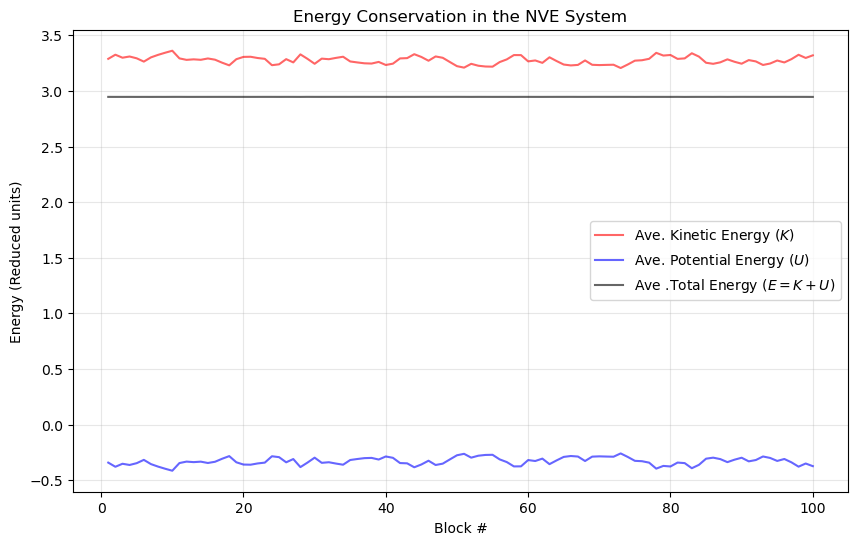

In [14]:
# Carico i dati
data5 = np.loadtxt("3/kinetic_energy2.dat")
data6 = np.loadtxt("3/potential_energy2.dat")
data7 = np.loadtxt("3/total_energy2.dat")

# Definisco le x (blocchi) e le y (energie)
blocks = data5[:, 0]
ke = data5[:, 1]
pe = data6[:, 1]
te=data7[:,1]

plt.figure(figsize=(10,6))

# Plot delle componenti
plt.plot(blocks, ke, label='Ave. Kinetic Energy ($K$)', color='red', alpha=0.6)
plt.plot(blocks, pe, label='Ave. Potential Energy ($U$)', color='blue', alpha=0.6)
plt.plot(blocks, te, label='Ave .Total Energy ($E=K+U$)', color='black', alpha=0.6)

# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

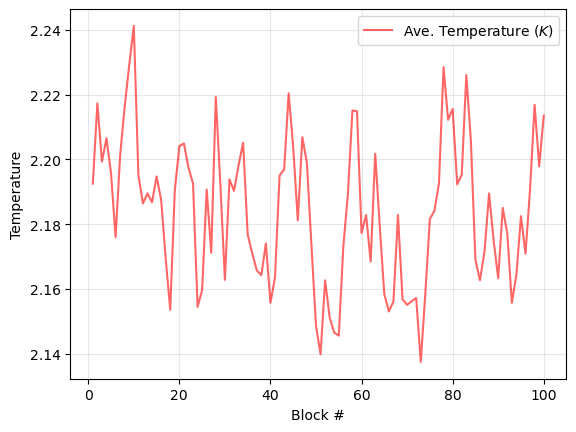

In [16]:
# Carico i dati
data8 = np.loadtxt("3/temperature2.dat")
te = data8[:,1]
blocks_te = data8[:, 0]

# Plot delle componenti
plt.plot(blocks_te, te, label='Ave. Temperature ($K$)', color='red', alpha=0.6)

plt.title("")
plt.xlabel("Block #")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


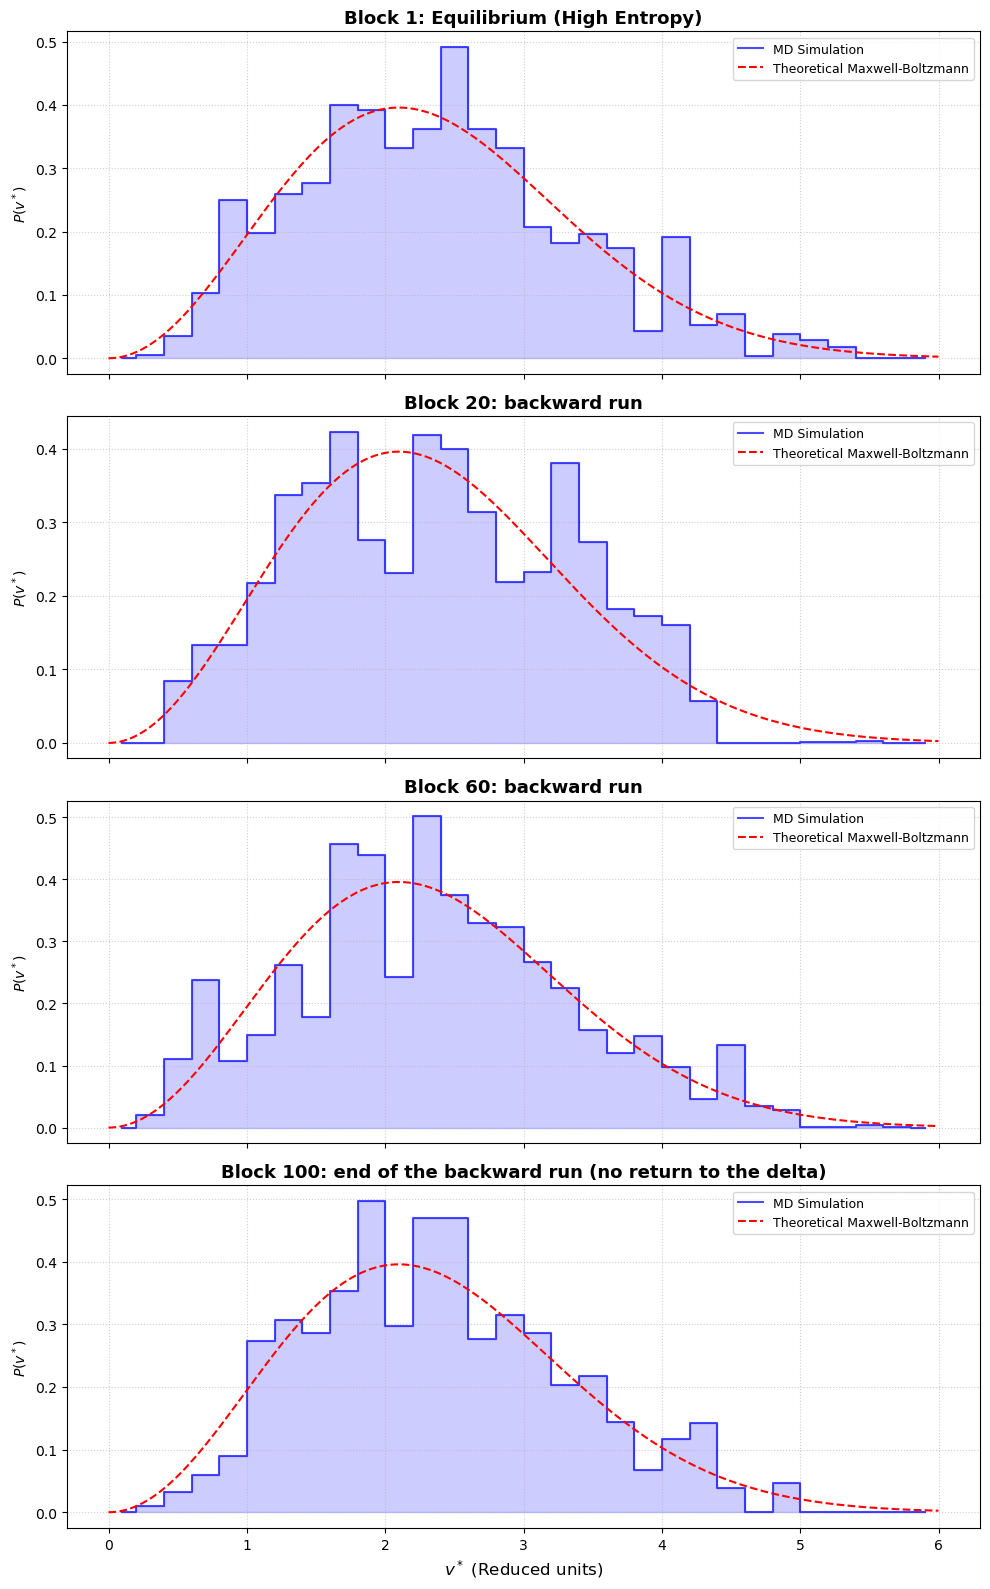

In [30]:
def plot_separated_histograms(filename):
    # Leggiamo il file e separiamo i blocchi
    with open(filename, 'r') as f:
        blocks = [b for b in f.read().split('\n\n\n') if b.strip()]

    indices = [len(blocks)-1, 60, 20, 0]
    titles = [
        'Block 1: Equilibrium (High Entropy)',
        'Block 20: backward run',
        'Block 60: backward run',
        'Block 100: end of the backward run (no return to the delta)'
    ]

    # Creiamo una figura con 4 grafici sovrapposti
    fig, axes = plt.subplots(4, 1, figsize=(10, 16), sharex=True)
    
    # Valore di Temperatura Effettiva (controlla il tuo temperature.dat!)
    T_eff = 2.2 
    v_range = np.linspace(0, 6, 200)
    maxwell = np.sqrt(2/np.pi) * (v_range**2 / (T_eff**1.5)) * np.exp(-(v_range**2)/(2*T_eff))

    for i, idx in enumerate(indices):
        data = np.genfromtxt(blocks[idx].splitlines())
        
        if data.size > 0:
            ax = axes[i]
            # Istogramma simulato
            ax.step(data[:, 0], data[:, 1], where='mid', color='blue', label='MD Simulation', alpha=0.7)
            ax.fill_between(data[:, 0], data[:, 1], step="mid", alpha=0.2, color='blue')
            
            # Curva teorica di confronto
            ax.plot(v_range, maxwell, 'r--', lw=1.5, label='Theoretical Maxwell-Boltzmann')
            
            ax.set_title(titles[i], fontsize=13, fontweight='bold')
            ax.set_ylabel("$P(v^*)$")
            ax.legend(loc='upper right', fontsize=9)
            ax.grid(True, linestyle=':', alpha=0.6)

    plt.xlabel("$v^*$ (Reduced units)", fontsize=12)
    plt.tight_layout()
    plt.show()

# Esegui il plot
plot_separated_histograms('3/pofv_evolution2.dat')   

## Comparison: Direct vs. Inverse Process

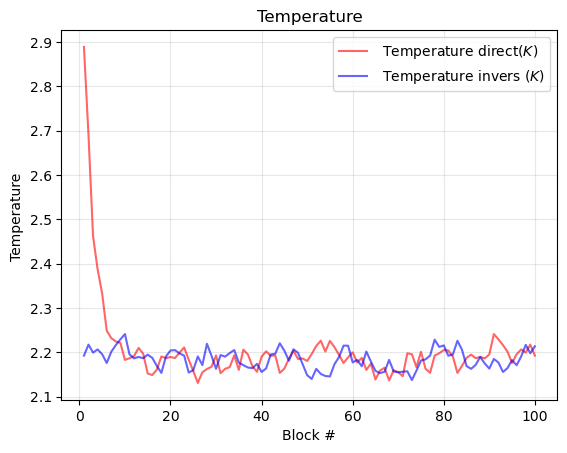

In [20]:
# Plot delle componenti
plt.plot(blocks, data4[:, 1]  , label=' Temperature direct($K$)', color='red', alpha=0.6)
plt.plot(blocks, data8[:, 1], label=' Temperature invers ($K$)', color='blue', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Temperature")
plt.xlabel("Block #")
plt.ylabel("Temperature ")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

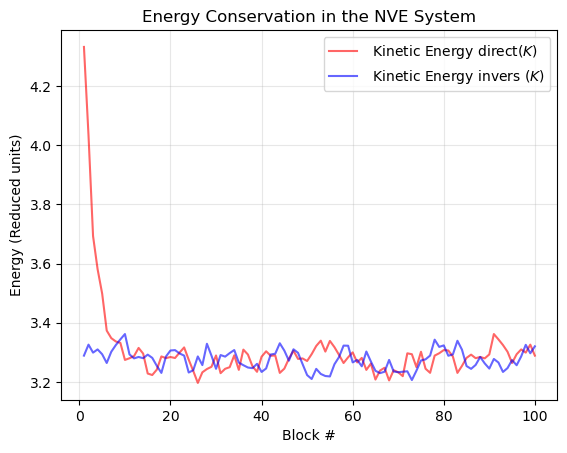

In [22]:
# Plot delle componenti
plt.plot(blocks, data1[:, 1]  , label=' Kinetic Energy direct($K$)', color='red', alpha=0.6)
plt.plot(blocks, data5[:, 1], label=' Kinetic Energy invers ($K$)', color='blue', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)



plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

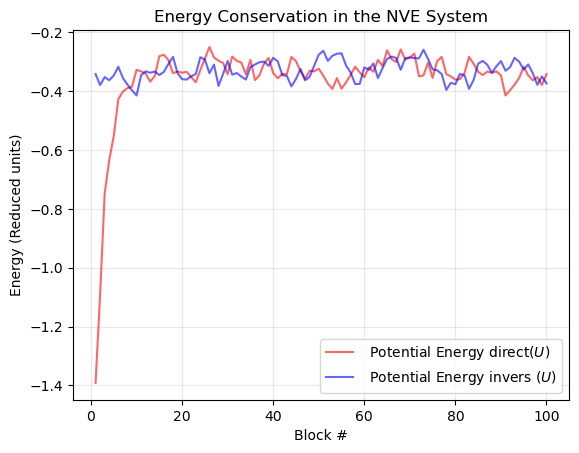

In [24]:
# Plot delle componenti
plt.plot(blocks, data2[:, 1]  , label=' Potential Energy direct($U$)', color='red', alpha=0.6)
plt.plot(blocks, data6[:, 1], label=' Potential Energy invers ($U$)', color='blue', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

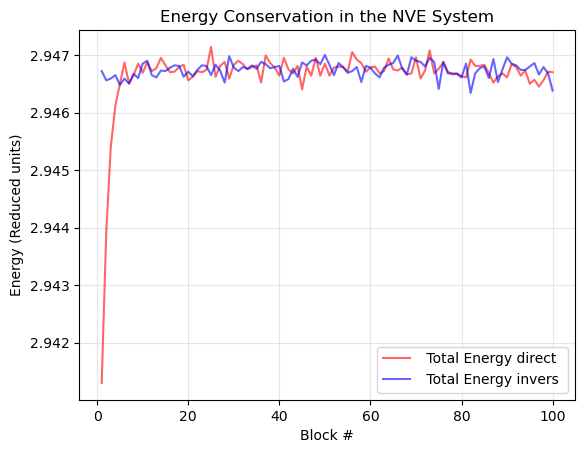

In [26]:
# Plot delle componenti
plt.plot(blocks, data3[:, 1]  , label=' Total Energy direct', color='red', alpha=0.6)
plt.plot(blocks, data7[:, 1], label=' Total Energy invers ', color='blue', alpha=0.6)
#plt.plot(blocks, data7[:, 1]-data3[:, 1], label=' Total Energy differance ', color='black', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

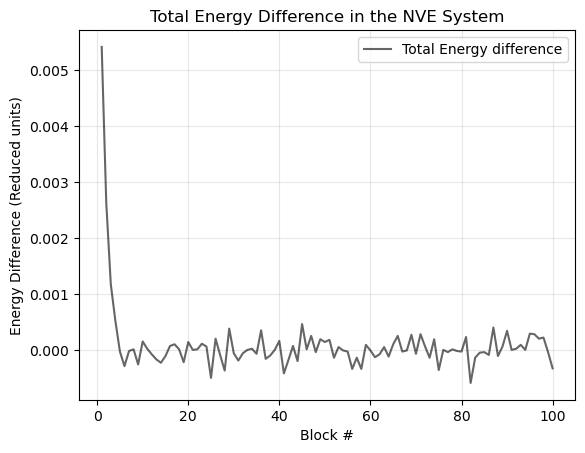

In [28]:
plt.plot(blocks, data7[:, 1] - data3[:, 1], label='Total Energy difference', color='black', alpha=0.6)
plt.title("Total Energy Difference in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy Difference (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()